# Projet Fil Rouge – Indicateurs de mortalité périnatale en France

**Mcharek Marwa, 2026**

## Data Cleaning

## Objectif

Dans ce notebook, je prépare et je nettoie les données relatives à la mortalité périnatale en France entre 2012 et 2023.

Mon objectif est de construire un jeu de données fiable et structuré qui pourra être utilisé dans mon application Streamlit. Ce travail me permettra également de réaliser des analyses statistiques, des requêtes SQL et des visualisations interactives afin de mieux explorer les indicateurs de santé périnatale.

# 1. Importation des données

## Importation des bibliothèques
- **Pandas** permettra de lire et manipuler les données Excel.
- Les autres bibliothèques seront ajoutées progressivement selon les besoins de l'analyse.

## Lecture du fichier Excel
Les données proviennent du fichier **mortinatalite_taux.xlsx**.
Ce fichier contient les principaux indicateurs de mortalité périnatale par région entre 2012 et 2023.


In [1]:
import pandas as pd

df = pd.read_excel(
    "../data/raw/mortinatalite_taux.xlsx",
    sheet_name=1,
    skiprows=5,
    header=[0, 1]
)


### Pourquoi utiliser ces paramètres ?
Le fichier Excel possède plusieurs lignes d'en-têtes.

J'utilise donc :

- `sheet_name=1` pour sélectionner la feuille contenant les données.
- `skiprows=5` pour ignorer les lignes de titre.
- `header=[0,1]` afin de conserver les deux niveaux d'en-têtes.

## Première exploration des données

Avant de commencer le nettoyage, il est important d'observer la structure générale du fichier.

Cette étape permet de vérifier :

- le nombre de lignes ;
- le nombre de colonnes ;
- la présence d'en-têtes multiples ;
- l'organisation générale du tableau.

In [2]:
df.head()

Unnamed: 0_level_0          Unnamed: 1_level_0                 2012  \
  Unnamed: 0_level_1           Zone géographique Mortinatalité totale   
0                NaN     Auvergne -  Rhône-Alpes             8.418929   
1                NaN  Bourgogne -  Franche-Comté             9.088887   
2                NaN                    Bretagne             7.702776   
3                NaN      Centre -  Val de Loire             9.928186   
4                NaN                       Corse            11.686144   

                                                                        2013  \
  Mortinatalité spontanée       IMG effectif naissances Mortinatalité totale   
0                5.043124  3.375805             97162.0             8.147808   
1                6.069851  3.019036             31467.0             8.044030   
2                3.864997  3.837779             36740.0             8.421405   
3                5.956912  3.971274             30217.0             8.565893   
4                9.015025  2.671119              2995.0            11.301370   

                                                          ...      2021  \
  Mortinatalité spontanée       IMG effectifs naissances  ...       IMG   
0                4.767667  3.380141              95854.0  ...  3.319207   
1                4.494236  3.549795              30706.0  ...  3.286642   
2                4.405901  4.015504              35861.0  ...  3.864373   
3                5.064754  3.501139              29419.0  ...  3.088109   
4                7.534247  3.767123               2920.0  ...  3.281079   

                                      2022                                    \
  effectif naissances Mortinatalité totale Mortinatalité spontanée       IMG   
0             87069.0             7.752395                4.736265  3.016129   
1             25558.0             8.847432                5.965011  2.882421   
2             32088.0             8.636960                4.286491  4.350469   
3             25582.0             7.881773                4.492611  3.389163   
4              2743.0             8.746356                5.466472  3.279883   

                                      2023                                    \
  effectif naissances Mortinatalité totale Mortinatalité spontanée       IMG   
0             84877.0             7.524454                4.514673  3.009782   
1             24979.0             8.052082                4.925475  3.126606   
2             31261.0             8.655927                4.431010  4.224917   
3             25375.0             9.641576                5.404471  4.237105   
4              2744.0            10.346200                5.571031  4.775169   

                       
  effectif naissances  
0             78411.0  
1             23348.0  
2             29113.0  
3             23129.0  
4              2513.0  

[5 rows x 50 columns]

# 2. Nettoyage des données

## Nettoyage des noms de colonnes

Les colonnes du fichier sont organisées sous forme de MultiIndex (année + indicateur).

Je fusionne les deux niveaux afin d'obtenir un nom de colonne unique, plus simple à manipuler avec Pandas et SQL.

Exemple :

- 2012 + Mortinatalité totale

devient

- 2012_mortinatalite_totale

In [3]:
# On transforme les colonnes multi-niveaux en colonnes simples
df.columns = [
    f"{annee}_{indicateur}"
    if "Unnamed" not in str(annee)
    else indicateur
    for annee, indicateur in df.columns
]

# Nettoyage des noms de colonnes
df.columns = (
    df.columns
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("é", "e")
    .str.replace("è", "e")
    .str.replace("à", "a")
    .str.replace("'", "_")
)

df.head()

,unnamed:_0_level_1,zone_geographique,2012_mortinatalite_totale,2012_mortinatalite_spontanee,2012_img,2012_effectif_naissances,2013_mortinatalite_totale,2013_mortinatalite_spontanee,2013_img,2013_effectifs_naissances,...,2021_img,2021_effectif_naissances,2022_mortinatalite_totale,2022_mortinatalite_spontanee,2022_img,2022_effectif_naissances,2023_mortinatalite_totale,2023_mortinatalite_spontanee,2023_img,2023_effectif_naissances
0,NaN,Auvergne - Rhône-Alpes,8.418929,5.043124,3.375805,97162.0,8.147808,4.767667,3.380141,95854.0,...,3.319207,87069.0,7.752395,4.736265,3.016129,84877.0,7.524454,4.514673,3.009782,78411.0
1,NaN,Bourgogne - Franche-Comté,9.088887,6.069851,3.019036,31467.0,8.044030,4.494236,3.549795,30706.0,...,3.286642,25558.0,8.847432,5.965011,2.882421,24979.0,8.052082,4.925475,3.126606,23348.0
2,NaN,Bretagne,7.702776,3.864997,3.837779,36740.0,8.421405,4.405901,4.015504,35861.0,...,3.864373,32088.0,8.636960,4.286491,4.350469,31261.0,8.655927,4.431010,4.224917,29113.0
3,NaN,Centre - Val de Loire,9.928186,5.956912,3.971274,30217.0,8.565893,5.064754,3.501139,29419.0,...,3.088109,25582.0,7.881773,4.492611,3.389163,25375.0,9.641576,5.404471,4.237105,23129.0
4,NaN,Corse,11.686144,9.015025,2.671119,2995.0,11.301370,7.534247,3.767123,2920.0,...,3.281079,2743.0,8.746356,5.466472,3.279883,2744.0,10.346200,5.571031,4.775169,2513.0


### Vérification des noms de colonnes

In [4]:
df.columns

Index(['unnamed:_0_level_1', 'zone_geographique', '2012_mortinatalite_totale',
       '2012_mortinatalite_spontanee', '2012_img', '2012_effectif_naissances',
       '2013_mortinatalite_totale', '2013_mortinatalite_spontanee', '2013_img',
       '2013_effectifs_naissances', '2014_mortinatalite_totale',
       '2014_mortinatalite_spontanee', '2014_img', '2014_effectif_naissances',
       '2015_mortinatalite_totale', '2015_mortinatalite_spontanee', '2015_img',
       '2015_effectif_naissances', '2016_mortinatalite_totale',
       '2016_mortinatalite_spontanee', '2016_img', '2016_effectif_naissances',
       '2017_mortinatalite_totale', '2017_mortinatalite_spontanee', '2017_img',
       '2017_effectif_naissances', '2018_mortinatalite_totale',
       '2018_mortinatalite_spontanee', '2018_img', '2018_effectif_naissances',
       '2019_mortinatalite_totale', '2019_mortinatalite_spontanee', '2019_img',
       '2019_effectif_naissances', '2020_mortinatalite_totale',
       '2020_mortinatalite_s

## Vérification de la structure des données
J'utilise la méthode `info()` afin de vérifier les types de données, le nombre de valeurs non nulles et la structure générale du DataFrame.

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 50 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   unnamed:_0_level_1            0 non-null      float64
 1   zone_geographique             23 non-null     str    
 2   2012_mortinatalite_totale     21 non-null     float64
 3   2012_mortinatalite_spontanee  21 non-null     float64
 4   2012_img                      21 non-null     float64
 5   2012_effectif_naissances      21 non-null     float64
 6   2013_mortinatalite_totale     21 non-null     float64
 7   2013_mortinatalite_spontanee  21 non-null     float64
 8   2013_img                      21 non-null     float64
 9   2013_effectifs_naissances     21 non-null     float64
 10  2014_mortinatalite_totale     21 non-null     float64
 11  2014_mortinatalite_spontanee  21 non-null     float64
 12  2014_img                      21 non-null     float64
 13  2014_effectif_nais

## Dimensions du jeu de données

J'affiche ensuite les dimensions du DataFrame afin de connaître le nombre de lignes et de colonnes présentes avant de poursuivre le nettoyage.

In [6]:
df.shape


(24, 50)

## Suppression des colonnes inutiles

In [7]:
df = df.drop(columns="unnamed:_0_level_1")

## Recherche des valeurs manquantes

In [8]:
df.isna().sum()

zone_geographique               1
2012_mortinatalite_totale       3
2012_mortinatalite_spontanee    3
2012_img                        3
2012_effectif_naissances        3
2013_mortinatalite_totale       3
2013_mortinatalite_spontanee    3
2013_img                        3
2013_effectifs_naissances       3
2014_mortinatalite_totale       3
2014_mortinatalite_spontanee    3
2014_img                        3
2014_effectif_naissances        3
2015_mortinatalite_totale       3
2015_mortinatalite_spontanee    3
2015_img                        3
2015_effectif_naissances        3
2016_mortinatalite_totale       3
2016_mortinatalite_spontanee    3
2016_img                        3
2016_effectif_naissances        3
2017_mortinatalite_totale       3
2017_mortinatalite_spontanee    3
2017_img                        3
2017_effectif_naissances        3
2018_mortinatalite_totale       3
2018_mortinatalite_spontanee    3
2018_img                        3
2018_effectif_naissances        3
2019_mortinata

## Traitement des valeurs manquantes

Avant de supprimer ou de remplacer les valeurs manquantes, je vérifie les lignes concernées afin de comprendre leur origine.

Cette étape me permet de distinguer les données réellement manquantes des lignes correspondant à des totaux, des séparateurs ou des informations non exploitables.

In [9]:
# Afficher les lignes contenant au moins une valeur manquante
df[df.isna().any(axis=1)]

,zone_geographique,2012_mortinatalite_totale,2012_mortinatalite_spontanee,2012_img,2012_effectif_naissances,2013_mortinatalite_totale,2013_mortinatalite_spontanee,2013_img,2013_effectifs_naissances,2014_mortinatalite_totale,...,2021_img,2021_effectif_naissances,2022_mortinatalite_totale,2022_mortinatalite_spontanee,2022_img,2022_effectif_naissances,2023_mortinatalite_totale,2023_mortinatalite_spontanee,2023_img,2023_effectif_naissances
21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,"*En 2017, les données du PMSI sont incomplètes...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23,**En 2019 les données du PMSI sont manifesteme...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Suppression des lignes non exploitables

Après avoir identifié les valeurs manquantes, je constate qu'elles correspondent à des lignes d'information présentes dans le fichier Excel et non à des observations.

Ces lignes contiennent des notes explicatives relatives aux données du PMSI et ne sont pas utiles pour l'analyse statistique. Je les supprime afin d'obtenir un jeu de données propre et directement exploitable.

In [10]:
# Suppression des lignes contenant une valeur manquante
df = df.dropna()

# Vérification
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 49 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   zone_geographique             21 non-null     str    
 1   2012_mortinatalite_totale     21 non-null     float64
 2   2012_mortinatalite_spontanee  21 non-null     float64
 3   2012_img                      21 non-null     float64
 4   2012_effectif_naissances      21 non-null     float64
 5   2013_mortinatalite_totale     21 non-null     float64
 6   2013_mortinatalite_spontanee  21 non-null     float64
 7   2013_img                      21 non-null     float64
 8   2013_effectifs_naissances     21 non-null     float64
 9   2014_mortinatalite_totale     21 non-null     float64
 10  2014_mortinatalite_spontanee  21 non-null     float64
 11  2014_img                      21 non-null     float64
 12  2014_effectif_naissances      21 non-null     float64
 13  2015_mortinatalite

(21, 49)

## Vérification des types de données

Une fois le nettoyage terminé, je vérifie les types de données de chaque colonne afin de m'assurer qu'ils sont cohérents avec les analyses que je souhaite réaliser.

Cette étape est essentielle avant d'enregistrer les données et de les exploiter avec SQLite et Streamlit.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 49 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   zone_geographique             21 non-null     str    
 1   2012_mortinatalite_totale     21 non-null     float64
 2   2012_mortinatalite_spontanee  21 non-null     float64
 3   2012_img                      21 non-null     float64
 4   2012_effectif_naissances      21 non-null     float64
 5   2013_mortinatalite_totale     21 non-null     float64
 6   2013_mortinatalite_spontanee  21 non-null     float64
 7   2013_img                      21 non-null     float64
 8   2013_effectifs_naissances     21 non-null     float64
 9   2014_mortinatalite_totale     21 non-null     float64
 10  2014_mortinatalite_spontanee  21 non-null     float64
 11  2014_img                      21 non-null     float64
 12  2014_effectif_naissances      21 non-null     float64
 13  2015_mortinatalite

## Organisation des données

Après le nettoyage, j'organise les données en plusieurs jeux de données (France entière, régions et DROM). Cette organisation facilitera les analyses SQL, les comparaisons géographiques et l'intégration des données dans l'application Streamlit.

In [12]:
df["zone_geographique"]

0            Auvergne -  Rhône-Alpes
1         Bourgogne -  Franche-Comté
2                           Bretagne
3             Centre -  Val de Loire
4                              Corse
5                          Grand Est
6                    Hauts-de-France
7                      Ile-de-France
8                          Normandie
9                 Nouvelle-Aquitaine
10                         Occitanie
11                  Pays de la Loire
12    Provence - Alpes - Côte d'Azur
13                   Total métropole
14                        Guadeloupe
15                            Guyane
16                        La Réunion
17                        Martinique
18                           Mayotte
19                        Total DROM
20              Total France entière
Name: zone_geographique, dtype: str

## Jeu de données : France entière

Je crée un premier jeu de données contenant uniquement les indicateurs de la France entière.

Ce DataFrame me permettra d'étudier l'évolution nationale de la mortinatalité entre 2012 et 2023 et de réaliser des comparaisons avec les autres niveaux géographiques.

In [13]:
df_france = df[df["zone_geographique"] == "Total France entière"].reset_index(drop=True)

df_france

,zone_geographique,2012_mortinatalite_totale,2012_mortinatalite_spontanee,2012_img,2012_effectif_naissances,2013_mortinatalite_totale,2013_mortinatalite_spontanee,2013_img,2013_effectifs_naissances,2014_mortinatalite_totale,...,2021_img,2021_effectif_naissances,2022_mortinatalite_totale,2022_mortinatalite_spontanee,2022_img,2022_effectif_naissances,2023_mortinatalite_totale,2023_mortinatalite_spontanee,2023_img,2023_effectif_naissances
0,Total France entière,9.23571,5.532037,3.703672,830758.0,8.984536,5.390478,3.594058,821634.0,8.792641,...,3.393319,742341.0,8.789205,5.399221,3.389984,727144.0,8.790916,5.30471,3.486206,676380.0


## Jeu de données : Régions métropolitaines

Je crée un deuxième jeu de données regroupant les treize régions métropolitaines.

Ce DataFrame sera utilisé pour comparer les indicateurs de mortinatalité entre les différentes régions françaises.

In [14]:
# Je sélectionne les 13 régions métropolitaines
# Elles correspondent aux lignes 0 à 12 du DataFrame df

df_regions = df.iloc[0:13].reset_index(drop=True)

# Vérification
print(df_regions.shape)
df_regions["zone_geographique"]

(13, 49)


0            Auvergne -  Rhône-Alpes
1         Bourgogne -  Franche-Comté
2                           Bretagne
3             Centre -  Val de Loire
4                              Corse
5                          Grand Est
6                    Hauts-de-France
7                      Ile-de-France
8                          Normandie
9                 Nouvelle-Aquitaine
10                         Occitanie
11                  Pays de la Loire
12    Provence - Alpes - Côte d'Azur
Name: zone_geographique, dtype: str

## Jeu de données : DROM

Je crée un troisième jeu de données regroupant les départements et régions d'outre-mer (DROM).

Ce DataFrame permettra d'étudier les indicateurs de mortinatalité dans les territoires ultramarins et de les comparer avec ceux de la métropole.

In [15]:
# Les DROM sont situés entre les lignes 14 et 18
# du DataFrame (la ligne 19 n'est pas incluse avec iloc).

df_drom = df.iloc[14:19].reset_index(drop=True)

# Affichage du DataFrame des DROM
df_drom

,zone_geographique,2012_mortinatalite_totale,2012_mortinatalite_spontanee,2012_img,2012_effectif_naissances,2013_mortinatalite_totale,2013_mortinatalite_spontanee,2013_img,2013_effectifs_naissances,2014_mortinatalite_totale,...,2021_img,2021_effectif_naissances,2022_mortinatalite_totale,2022_mortinatalite_spontanee,2022_img,2022_effectif_naissances,2023_mortinatalite_totale,2023_mortinatalite_spontanee,2023_img,2023_effectif_naissances
0,Guadeloupe,16.428295,10.630073,5.798222,5142.0,16.902516,13.168239,3.734277,5088.0,16.235101,...,3.955328,4298.0,18.341893,14.918073,3.423820,4089.0,17.629024,14.818600,2.810424,3914.0
1,Guyane,15.494636,12.961859,2.532777,6712.0,17.779839,14.687693,3.092146,6468.0,14.596173,...,3.295094,8194.0,14.006682,11.822154,2.184528,7783.0,15.116279,12.532300,2.583979,7740.0
2,La Réunion,11.686605,7.468363,4.218242,14461.0,11.719853,8.401581,3.318272,14164.0,9.820426,...,3.031199,13526.0,8.964218,5.197740,3.766478,13275.0,8.842073,6.612333,2.229740,13006.0
3,Martinique,16.461809,11.194030,5.267779,4556.0,17.762842,11.041767,6.721075,4166.0,15.454545,...,4.411359,3627.0,18.932874,13.195640,5.737235,3486.0,13.110846,9.833135,3.277712,3356.0
4,Mayotte,14.679715,12.603796,2.075919,6744.0,13.749813,12.703632,1.046181,6691.0,15.360546,...,2.903319,10333.0,18.270165,16.715258,1.554908,10290.0,15.641078,14.200453,1.440626,9718.0


## Vérification des jeux de données

Je vérifie les dimensions de chaque DataFrame afin de m'assurer que les données ont été correctement réparties entre la France entière, les régions métropolitaines et les DROM.

In [16]:
print(df_france.shape)
print(df_regions.shape)
print(df_drom.shape)

(1, 49)
(13, 49)
(5, 49)


## Sauvegarde des jeux de données nettoyés

Après le nettoyage des données, j'enregistre le jeu de données au format CSV.

Cette version nettoyée sera utilisée dans les étapes suivantes du projet, notamment pour la création de la base de données SQLite et le développement de l'application Streamlit.

In [17]:
df_france.to_csv("../data/processed/mortinatalite_france.csv", index=False)
df_regions.to_csv("../data/processed/mortinatalite_regions.csv", index=False)
df_drom.to_csv("../data/processed/mortinatalite_drom.csv", index=False)

# 3. Analyse avec SQLite
## Objectif

Après avoir nettoyé et organisé les données, je les intègre dans une base de données SQLite.

Cette étape me permet de centraliser les différents jeux de données, de réaliser des requêtes SQL et de préparer les informations qui seront utilisées dans l'application Streamlit.

## Importation des bibliothèques nécessaires
Pour travailler avec SQLite, j’importe la bibliothèque `sqlite3`.

J’utilise également `pandas`, car il me permet d’envoyer mes DataFrames vers la base de données et de lire les résultats des requêtes SQL sous forme de tableaux.

In [18]:
import sqlite3
import pandas as pd

## Création de la base de données SQLite

Je crée une base de données nommée **perinatalite.db**.

Cette base de données regroupera les différents jeux de données de mon projet (naissances, mortinatalité et prématurité), ce qui facilitera leur organisation et leur exploitation avec SQL.


In [19]:
# Création de la connexion à la base SQLite
conn = sqlite3.connect("../data/perinatalite.db")

## Vérification de la connexion

Je vérifie que la connexion à la base de données est correctement établie avant d'y enregistrer les différents jeux de données.

In [20]:
print(conn)

## Enregistrement des jeux de données dans SQLite

Après avoir créé la base de données, j'y enregistre les différents jeux de données nettoyés.

Chaque DataFrame est enregistré sous la forme d'une table SQLite. Cette organisation me permettra d'interroger facilement les données à l'aide du langage SQL et de les réutiliser dans mon application Streamlit.

In [21]:
# Enregistrement du DataFrame France
df_france.to_sql(
    name="mortinatalite_france",
    con=conn,
    if_exists="replace",
    index=False
)

# Enregistrement du DataFrame des régions
df_regions.to_sql(
    name="mortinatalite_regions",
    con=conn,
    if_exists="replace",
    index=False
)

# Enregistrement du DataFrame des DROM
df_drom.to_sql(
    name="mortinatalite_drom",
    con=conn,
    if_exists="replace",
    index=False
)

5

## Vérification des tables créées

Avant d'exécuter des requêtes SQL, je vérifie que les différents jeux de données ont bien été enregistrés dans la base SQLite.

Cette étape permet de contrôler que les tables ont été correctement créées et qu'elles sont prêtes à être interrogées.

In [22]:
# Création d'un curseur pour exécuter des requêtes SQL
cursor = conn.cursor()

# Afficher toutes les tables présentes dans la base de données
cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")

# Affichage des tables
cursor.fetchall()

[('mortinatalite_france',),
 ('mortinatalite_regions',),
 ('mortinatalite_drom',)]

## Requêtes SQL

J'utilise plusieurs requêtes SQL afin d'explorer les données, répondre à des questions d'analyse et préparer les informations qui seront affichées dans l'application Streamlit.

## Première requête SQL : afficher le contenu d'une table

Après avoir vérifié que les tables ont bien été créées, je réalise une première requête SQL afin d'afficher le contenu de la table `mortinatalite_regions`.

Cette étape me permet de vérifier que les données ont été correctement enregistrées dans SQLite avant de réaliser des analyses plus avancées.

In [23]:
# Requête SQL pour afficher toutes les données de la table des régions

query = """
SELECT *
FROM mortinatalite_regions;
"""

# Exécution de la requête et affichage du résultat
pd.read_sql_query(query, conn)

,zone_geographique,2012_mortinatalite_totale,2012_mortinatalite_spontanee,2012_img,2012_effectif_naissances,2013_mortinatalite_totale,2013_mortinatalite_spontanee,2013_img,2013_effectifs_naissances,2014_mortinatalite_totale,...,2021_img,2021_effectif_naissances,2022_mortinatalite_totale,2022_mortinatalite_spontanee,2022_img,2022_effectif_naissances,2023_mortinatalite_totale,2023_mortinatalite_spontanee,2023_img,2023_effectif_naissances
0,Auvergne - Rhône-Alpes,8.418929,5.043124,3.375805,97162.0,8.147808,4.767667,3.380141,95854.0,7.829712,...,3.319207,87069.0,7.752395,4.736265,3.016129,84877.0,7.524454,4.514673,3.009782,78411.0
1,Bourgogne - Franche-Comté,9.088887,6.069851,3.019036,31467.0,8.044030,4.494236,3.549795,30706.0,8.145302,...,3.286642,25558.0,8.847432,5.965011,2.882421,24979.0,8.052082,4.925475,3.126606,23348.0
2,Bretagne,7.702776,3.864997,3.837779,36740.0,8.421405,4.405901,4.015504,35861.0,7.943037,...,3.864373,32088.0,8.636960,4.286491,4.350469,31261.0,8.655927,4.431010,4.224917,29113.0
3,Centre - Val de Loire,9.928186,5.956912,3.971274,30217.0,8.565893,5.064754,3.501139,29419.0,8.246364,...,3.088109,25582.0,7.881773,4.492611,3.389163,25375.0,9.641576,5.404471,4.237105,23129.0
4,Corse,11.686144,9.015025,2.671119,2995.0,11.301370,7.534247,3.767123,2920.0,13.567174,...,3.281079,2743.0,8.746356,5.466472,3.279883,2744.0,10.346200,5.571031,4.775169,2513.0
5,Grand Est,9.023480,5.700698,3.322782,63501.0,8.516104,5.455382,3.060723,63057.0,7.916534,...,2.972607,53152.0,8.732438,5.491733,3.240705,51532.0,8.281573,4.893657,3.387916,47817.0
6,Hauts-de-France,8.967667,5.256908,3.710759,80846.0,9.153062,5.554103,3.598959,80301.0,8.518772,...,3.433242,65827.0,9.048584,5.150732,3.897852,64651.0,8.452793,4.893722,3.559071,60690.0
7,Ile-de-France,9.986197,6.125894,3.860303,181851.0,9.369770,5.582225,3.787545,181648.0,9.708211,...,3.378459,168124.0,9.275146,5.788571,3.486576,163771.0,9.487468,5.893040,3.594429,153571.0
8,Normandie,8.643667,4.857392,3.786275,40145.0,8.577925,4.831542,3.746383,38704.0,8.583351,...,3.361345,33320.0,7.640476,4.542173,3.098303,33244.0,7.347635,4.887489,2.460146,30486.0
9,Nouvelle-Aquitaine,8.614082,4.531974,4.082109,60016.0,8.471853,4.582579,3.889274,59137.0,8.098812,...,3.780823,54221.0,7.963235,4.353731,3.609504,53747.0,8.255411,4.239265,4.016146,49301.0


## Sélection de colonnes

Je sélectionne uniquement les colonnes utiles à mon analyse afin d'alléger le résultat de la requête.

Cette étape permet de travailler uniquement sur les informations pertinentes et d'améliorer la lisibilité des résultats.

In [24]:
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale",
    "2023_effectif_naissances"
FROM mortinatalite_regions;
"""

pd.read_sql_query(query, conn)

,zone_geographique,2023_mortinatalite_totale,2023_effectif_naissances
0,Auvergne - Rhône-Alpes,7.524454,78411.0
1,Bourgogne - Franche-Comté,8.052082,23348.0
2,Bretagne,8.655927,29113.0
3,Centre - Val de Loire,9.641576,23129.0
4,Corse,10.346200,2513.0
5,Grand Est,8.281573,47817.0
6,Hauts-de-France,8.452793,60690.0
7,Ile-de-France,9.487468,153571.0
8,Normandie,7.347635,30486.0
9,Nouvelle-Aquitaine,8.255411,49301.0


## Trier les régions selon le taux de mortinatalité

Je classe les régions du taux de mortinatalité le plus élevé au plus faible.

Ce classement permet d'identifier rapidement les régions présentant les valeurs les plus importantes.

In [25]:
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" DESC;
"""

pd.read_sql_query(query, conn)

,zone_geographique,2023_mortinatalite_totale
0,Corse,10.346200
1,Centre - Val de Loire,9.641576
2,Ile-de-France,9.487468
3,Provence - Alpes - Côte d'Azur,8.782568
4,Bretagne,8.655927
5,Occitanie,8.545872
6,Hauts-de-France,8.452793
7,Grand Est,8.281573
8,Nouvelle-Aquitaine,8.255411
9,Bourgogne - Franche-Comté,8.052082


## Filtrer les régions

Je sélectionne uniquement les régions dont le taux de mortinatalité dépasse 8 ‰.

Le filtrage permet de cibler uniquement les observations répondant à un critère précis.

In [26]:
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
WHERE "2023_mortinatalite_totale" > 8;
"""

pd.read_sql_query(query, conn)

,zone_geographique,2023_mortinatalite_totale
0,Bourgogne - Franche-Comté,8.052082
1,Bretagne,8.655927
2,Centre - Val de Loire,9.641576
3,Corse,10.346200
4,Grand Est,8.281573
5,Hauts-de-France,8.452793
6,Ile-de-France,9.487468
7,Nouvelle-Aquitaine,8.255411
8,Occitanie,8.545872
9,Provence - Alpes - Côte d'Azur,8.782568


## Calcul de la moyenne

J'utilise une fonction d'agrégation afin de calculer le taux moyen de mortinatalité des régions en 2023.

Les fonctions d'agrégation sont très utilisées en analyse de données pour produire des indicateurs synthétiques.

In [27]:
query = """
SELECT
AVG("2023_mortinatalite_totale") AS moyenne_mortinatalite
FROM mortinatalite_regions;
"""

pd.read_sql_query(query, conn)

,moyenne_mortinatalite
0,8.529484


## Région présentant le taux de mortinatalité le plus élevé

J'identifie la région ayant enregistré le taux de mortinatalité total le plus élevé en 2023.

Pour cela, je trie les régions par ordre décroissant à l'aide de la clause `ORDER BY` puis je sélectionne uniquement la première ligne avec `LIMIT 1`.

Cette requête permet d'identifier rapidement la région la plus concernée par cet indicateur.

In [28]:
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" DESC
LIMIT 1;
"""

pd.read_sql_query(query, conn)

,zone_geographique,2023_mortinatalite_totale
0,Corse,10.3462


## Région présentant le taux de mortinatalité le plus faible

J'identifie la région ayant enregistré le taux de mortinatalité total le plus faible en 2023.

Je trie les régions par ordre croissant, puis je conserve uniquement la première ligne grâce à la clause `LIMIT 1`.

Cette requête permet de repérer la région présentant le niveau de mortinatalité le plus faible parmi les régions étudiées.

In [29]:
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" ASC
LIMIT 1;
"""

pd.read_sql_query(query, conn)

,zone_geographique,2023_mortinatalite_totale
0,Normandie,7.347635


## Préparation des résultats pour les visualisations

Les requêtes SQL précédentes permettent d'extraire les informations les plus pertinentes de la base de données.

Dans cette étape, j'enregistre les résultats des principales requêtes dans des DataFrames Pandas afin de pouvoir les réutiliser pour créer des visualisations interactives avec Plotly et les intégrer dans mon application Streamlit.

In [30]:
#Classement des régions
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" DESC;
"""

classement_regions = pd.read_sql_query(query, conn)

classement_regions

,zone_geographique,2023_mortinatalite_totale
0,Corse,10.346200
1,Centre - Val de Loire,9.641576
2,Ile-de-France,9.487468
3,Provence - Alpes - Côte d'Azur,8.782568
4,Bretagne,8.655927
5,Occitanie,8.545872
6,Hauts-de-France,8.452793
7,Grand Est,8.281573
8,Nouvelle-Aquitaine,8.255411
9,Bourgogne - Franche-Comté,8.052082


In [31]:
#Régions dont le taux est supérieur à 8 ‰
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
WHERE "2023_mortinatalite_totale" > 8
ORDER BY "2023_mortinatalite_totale" DESC;
"""

regions_sup_8 = pd.read_sql_query(query, conn)

regions_sup_8

,zone_geographique,2023_mortinatalite_totale
0,Corse,10.346200
1,Centre - Val de Loire,9.641576
2,Ile-de-France,9.487468
3,Provence - Alpes - Côte d'Azur,8.782568
4,Bretagne,8.655927
5,Occitanie,8.545872
6,Hauts-de-France,8.452793
7,Grand Est,8.281573
8,Nouvelle-Aquitaine,8.255411
9,Bourgogne - Franche-Comté,8.052082


In [32]:
#Région ayant le taux le plus élevé
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" DESC
LIMIT 1;
"""

region_max = pd.read_sql_query(query, conn)

region_max

,zone_geographique,2023_mortinatalite_totale
0,Corse,10.3462


In [33]:
#Région ayant le taux le plus faible
query = """
SELECT
    zone_geographique,
    "2023_mortinatalite_totale"
FROM mortinatalite_regions
ORDER BY "2023_mortinatalite_totale" ASC
LIMIT 1;
"""

region_min = pd.read_sql_query(query, conn)

region_min

,zone_geographique,2023_mortinatalite_totale
0,Normandie,7.347635


In [34]:
#Moyenne nationale
query = """
SELECT
AVG("2023_mortinatalite_totale") AS moyenne_mortinatalite
FROM mortinatalite_regions;
"""

moyenne_mortinatalite = pd.read_sql_query(query, conn)

moyenne_mortinatalite

,moyenne_mortinatalite
0,8.529484


In [35]:
# Afficher la liste de toutes les tables de la base SQLite

query = """
SELECT name
FROM sqlite_master
WHERE type='table';
"""

tables = pd.read_sql_query(query, conn)

tables

,name
0,mortinatalite_france
1,mortinatalite_regions
2,mortinatalite_drom


## Fermeture de la connexion

Une fois les requêtes terminées, je ferme la connexion à la base de données SQLite.

Cette étape permet de libérer les ressources utilisées et constitue une bonne pratique lors de l'utilisation d'une base de données.

In [36]:
# Fermeture de la connexion SQLite
conn.close()

# 4. Visualisation des données

Cette partie transforme les résultats issus de Pandas et de SQLite en visualisations complémentaires.  
Les graphiques ont été choisis pour répondre à différentes questions :

- comparer les régions ;
- suivre une évolution nationale ;
- comparer plusieurs indicateurs ;
- analyser la distribution des taux ;
- observer simultanément les régions et les années ;
- étudier la relation entre plusieurs variables.

Les graphiques Plotly sont interactifs et pourront être intégrés dans Streamlit avec `st.plotly_chart()`.


In [37]:
# Bibliothèques nécessaires pour l'ensemble de la partie visualisation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import statsmodels.api as sm


## 4.1 Classement régional du taux de mortinatalité en 2023 — barres horizontales Plotly

### Choix de la technique

Les barres horizontales facilitent la lecture des noms de régions et rendent le classement immédiatement visible.  
La couleur représente également le niveau du taux, tandis que les infobulles donnent les valeurs exactes.


In [38]:
# Sécurisation des types et tri des données
classement_regions = classement_regions.copy()

classement_regions["2023_mortinatalite_totale"] = pd.to_numeric(
    classement_regions["2023_mortinatalite_totale"],
    errors="coerce"
)

classement_regions = (
    classement_regions
    .dropna(subset=["2023_mortinatalite_totale"])
    .sort_values("2023_mortinatalite_totale", ascending=True)
)

# Création du graphique interactif
fig = px.bar(
    classement_regions,
    x="2023_mortinatalite_totale",
    y="zone_geographique",
    orientation="h",
    color="2023_mortinatalite_totale",
    text="2023_mortinatalite_totale",
    title="Taux de mortinatalité totale par région en 2023",
    labels={
        "zone_geographique": "Région",
        "2023_mortinatalite_totale": "Taux de mortinatalité"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    hovertemplate="<b>%{y}</b><br>Taux : %{x:.2f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    coloraxis_showscale=False,
    margin=dict(r=70)
)

fig.show()


### Interprétation

Le classement met en évidence des écarts régionaux en 2023. La Corse présente le taux le plus élevé parmi les régions représentées, tandis que la Normandie et les Pays de la Loire figurent parmi les valeurs les plus faibles.

Ces comparaisons doivent rester prudentes : un taux élevé dans une région à faible effectif peut être plus sensible aux variations annuelles. Le graphique décrit une situation en 2023 et ne suffit pas, seul, à établir une tendance durable.


## 4.2 Évolution du taux national — courbe Plotly avec repères

### Choix de la technique

Une courbe chronologique permet d'observer la tendance générale et les variations annuelles.  
La préparation convertit les colonnes annuelles en **format long**, structure plus adaptée à Plotly et à Streamlit.


In [39]:
# Passage du format large au format long
evolution = pd.DataFrame({
    "Année": list(range(2012, 2024)),
    "Taux de mortinatalité": [
        pd.to_numeric(
            df_france[f"{annee}_mortinatalite_totale"].iloc[0],
            errors="coerce"
        )
        for annee in range(2012, 2024)
    ]
}).dropna()

# Repérage automatique des valeurs minimale et maximale
ligne_min = evolution.loc[evolution["Taux de mortinatalité"].idxmin()]
ligne_max = evolution.loc[evolution["Taux de mortinatalité"].idxmax()]

fig = px.line(
    evolution,
    x="Année",
    y="Taux de mortinatalité",
    markers=True,
    title="Évolution du taux de mortinatalité en France (2012-2023)"
)

fig.add_annotation(
    x=ligne_max["Année"],
    y=ligne_max["Taux de mortinatalité"],
    text=f"Maximum : {ligne_max['Taux de mortinatalité']:.2f}",
    showarrow=True,
    yshift=18
)

fig.add_annotation(
    x=ligne_min["Année"],
    y=ligne_min["Taux de mortinatalité"],
    text=f"Minimum : {ligne_min['Taux de mortinatalité']:.2f}",
    showarrow=True,
    yshift=-25
)

fig.update_traces(
    hovertemplate="Année : %{x}<br>Taux : %{y:.2f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Année",
    yaxis_title="Taux de mortinatalité",
    hovermode="x unified"
)

fig.show()


### Interprétation

Le taux national présente une tendance globale à la baisse entre 2012 et 2023, mais l'évolution n'est pas parfaitement linéaire.  
Le maximum est observé en 2012. Le niveau le plus faible apparaît en 2019, avant une remontée en 2020 puis une nouvelle diminution.

Les annotations permettent d'identifier automatiquement les deux valeurs extrêmes sans les coder manuellement.


## 4.3 Comparaison des trois indicateurs — courbes multiples Plotly

### Choix de la technique

Des courbes multiples permettent de comparer l'évolution de la mortinatalité totale, de la mortinatalité spontanée et des IMG sur une même échelle temporelle.

Le passage au format long avec `melt()` améliore la structure des données : une colonne contient l'indicateur et une autre sa valeur.


In [40]:
# Construction du tableau annuel
comparaison_indicateurs = pd.DataFrame({
    "Année": list(range(2012, 2024)),
    "Mortinatalité totale": [
        pd.to_numeric(df_france[f"{annee}_mortinatalite_totale"].iloc[0], errors="coerce")
        for annee in range(2012, 2024)
    ],
    "Mortinatalité spontanée": [
        pd.to_numeric(df_france[f"{annee}_mortinatalite_spontanee"].iloc[0], errors="coerce")
        for annee in range(2012, 2024)
    ],
    "IMG": [
        pd.to_numeric(df_france[f"{annee}_img"].iloc[0], errors="coerce")
        for annee in range(2012, 2024)
    ]
})

# Transformation au format long
indicateurs_long = comparaison_indicateurs.melt(
    id_vars="Année",
    var_name="Indicateur",
    value_name="Taux"
).dropna()

# Création des courbes
fig = px.line(
    indicateurs_long,
    x="Année",
    y="Taux",
    color="Indicateur",
    markers=True,
    title="Évolution des indicateurs de mortinatalité en France (2012-2023)"
)

fig.update_traces(
    hovertemplate="Année : %{x}<br>Taux : %{y:.2f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Année",
    yaxis_title="Taux",
    legend_title="Indicateur",
    hovermode="x unified"
)

fig.show()


### Interprétation

La mortinatalité totale reste supérieure aux deux composantes sur toute la période, puisqu'elle regroupe la mortinatalité spontanée et les IMG.

La mortinatalité spontanée demeure la composante principale. Les IMG présentent des valeurs plus faibles. Les trois séries montrent globalement une diminution, avec une rupture visible autour de 2019-2020.


## 4.4 Distribution des taux régionaux — Boxplot Plotly

### Choix de la technique

Le **boxplot** complète les moyennes et les classements en décrivant la distribution :

- la médiane ;
- les quartiles ;
- l'étendue des valeurs ;
- les observations potentiellement atypiques.

Ici, toutes les valeurs régionales entre 2012 et 2023 sont rassemblées dans un tableau au format long.


In [41]:
# Sélection des colonnes annuelles de mortinatalité totale
colonnes_taux = sorted(
    [
        col for col in df_regions.columns
        if col.endswith("_mortinatalite_totale")
    ],
    key=lambda col: int(col.split("_")[0])
)

# Passage au format long
distribution_taux = df_regions[
    ["zone_geographique"] + colonnes_taux
].melt(
    id_vars="zone_geographique",
    value_vars=colonnes_taux,
    var_name="Année",
    value_name="Taux"
)

distribution_taux["Année"] = (
    distribution_taux["Année"]
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

distribution_taux["Taux"] = pd.to_numeric(
    distribution_taux["Taux"],
    errors="coerce"
)

distribution_taux = distribution_taux.dropna()

# Création du boxplot
fig = px.box(
    distribution_taux,
    x="Année",
    y="Taux",
    points="outliers",
    title="Distribution des taux régionaux de mortinatalité par année"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Année",
    yaxis_title="Taux de mortinatalité"
)

fig.show()


### Interprétation

Le boxplot permet d'observer la dispersion des taux régionaux pour chaque année.  
La ligne située au centre de chaque boîte représente la médiane, tandis que la hauteur de la boîte décrit l'intervalle interquartile.

Les points isolés signalent des valeurs éloignées du reste de la distribution. Ils ne doivent pas être automatiquement considérés comme des erreurs : ils peuvent correspondre à une situation régionale particulière ou à un faible effectif.


## 4.5 Taux de mortinatalité par région et par année — Heatmap Seaborn

### Choix de la technique

La Heatmap fournit une vue d'ensemble des différences territoriales et temporelles.  
Chaque cellule correspond à une combinaison région-année et la couleur représente le niveau du taux.

Elle permet de détecter rapidement des régions durablement au-dessus ou au-dessous des autres, ainsi que des années particulières.


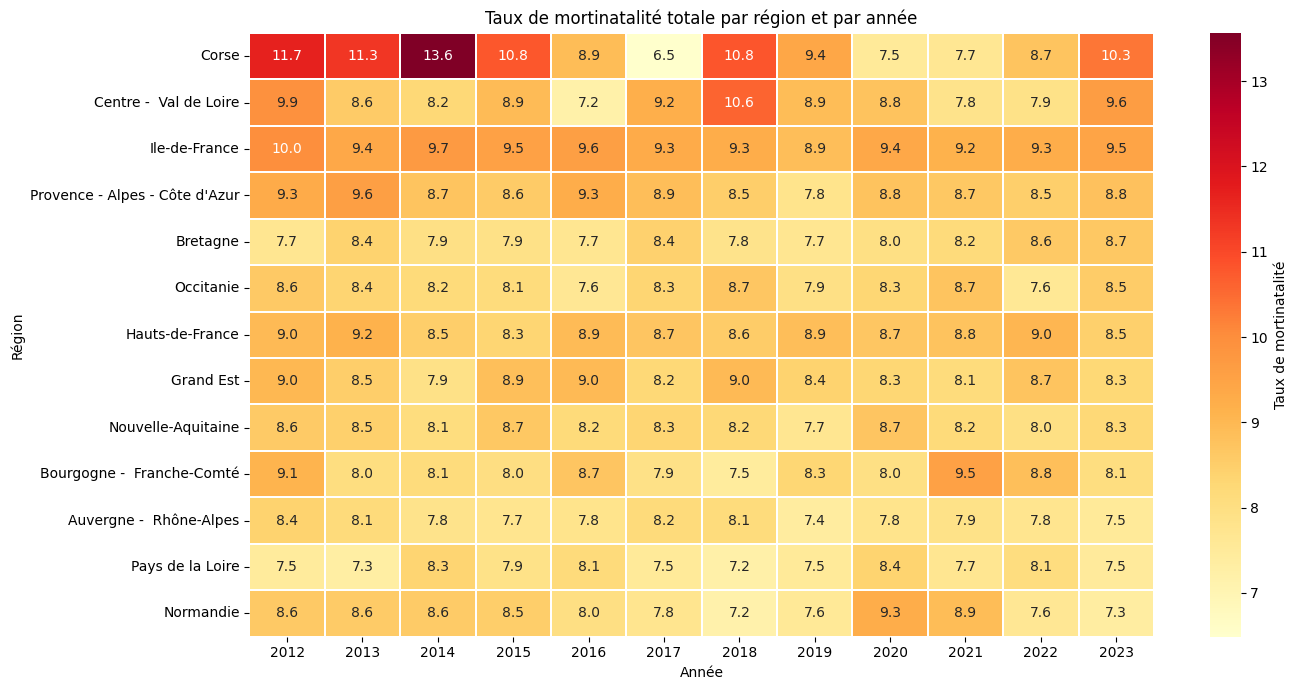

In [42]:
# Création de la matrice régions × années
heatmap_taux = (
    df_regions
    .set_index("zone_geographique")[colonnes_taux]
    .apply(pd.to_numeric, errors="coerce")
)

heatmap_taux.columns = [
    int(col.split("_")[0]) for col in heatmap_taux.columns
]

# Tri selon le taux de 2023
heatmap_taux = heatmap_taux.sort_values(
    by=2023,
    ascending=False
)

# Création de la Heatmap
plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_taux,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "Taux de mortinatalité"}
)

plt.title("Taux de mortinatalité totale par région et par année")
plt.xlabel("Année")
plt.ylabel("Région")
plt.tight_layout()
plt.show()


### Interprétation

La Heatmap met en évidence des écarts entre régions et des variations d'une année à l'autre.  
Les cellules les plus foncées correspondent aux taux les plus élevés. Certaines régions présentent ponctuellement des valeurs supérieures, mais les positions ne restent pas nécessairement identiques sur toute la période.

Cette visualisation invite donc à privilégier une lecture pluriannuelle plutôt qu'une conclusion fondée uniquement sur 2023.


## 4.6 Relation entre naissances et mortinatalité — Bubble chart avec régression

### Choix de la technique

Le **Bubble chart** étudie simultanément trois variables régionales en 2023 :

- axe X : nombre de naissances ;
- axe Y : taux de mortinatalité totale ;
- taille de la bulle : taux de mortinatalité spontanée.

La droite de régression fournit un repère visuel sur le sens de l'association. Elle ne démontre toutefois pas une relation causale.


In [43]:
# Sélection des variables nécessaires
bubble_df = df_regions[[
    "zone_geographique",
    "2023_effectif_naissances",
    "2023_mortinatalite_totale",
    "2023_mortinatalite_spontanee"
]].copy()

# Conversion en numérique
colonnes_numeriques = [
    "2023_effectif_naissances",
    "2023_mortinatalite_totale",
    "2023_mortinatalite_spontanee"
]

for colonne in colonnes_numeriques:
    bubble_df[colonne] = pd.to_numeric(
        bubble_df[colonne],
        errors="coerce"
    )

bubble_df = bubble_df.dropna(subset=colonnes_numeriques)

# Création du graphique
fig = px.scatter(
    bubble_df,
    x="2023_effectif_naissances",
    y="2023_mortinatalite_totale",
    size="2023_mortinatalite_spontanee",
    color="2023_mortinatalite_totale",
    hover_name="zone_geographique",
    trendline="ols",
    size_max=35,
    title=(
        "Relation entre le nombre de naissances et "
        "le taux de mortinatalité en 2023"
    ),
    labels={
        "2023_effectif_naissances": "Nombre de naissances",
        "2023_mortinatalite_totale": "Taux de mortinatalité totale",
        "2023_mortinatalite_spontanee": "Mortinatalité spontanée"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

# Calcul du coefficient de corrélation linéaire
correlation = bubble_df[
    "2023_effectif_naissances"
].corr(
    bubble_df["2023_mortinatalite_totale"]
)

print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")


Coefficient de corrélation de Pearson : 0.004


### Interprétation

Les points sont assez dispersés et la droite de régression est légèrement descendante. Cela suggère une association linéaire faible entre le volume des naissances et le taux de mortinatalité en 2023.

Le coefficient de corrélation affiché sous le graphique permet de quantifier cette relation :

- proche de 0 : relation linéaire faible ;
- proche de 1 : relation positive forte ;
- proche de -1 : relation négative forte.

Cette analyse reste descriptive. Le nombre de naissances ne suffit pas à expliquer les écarts de mortinatalité, qui peuvent dépendre de nombreux facteurs médicaux, démographiques et organisationnels.


## Conclusion de l'analyse de la mortinatalité

L'analyse montre une diminution globale du taux national entre 2012 et 2023, accompagnée de fluctuations annuelles et d'écarts régionaux.

Le notebook mobilise plusieurs compétences techniques :

- extraction et agrégation avec SQL ;
- préparation des données avec Pandas ;
- transformation du format large vers le format long ;
- visualisations interactives avec Plotly ;
- analyse de distribution avec un boxplot ;
- comparaison spatio-temporelle avec une Heatmap ;
- analyse de relation avec une régression et un coefficient de corrélation.

Ces éléments sont directement réutilisables pour construire les filtres et les graphiques de l'application Streamlit.
